In [18]:
# # Get imports and functions needed

# from sunpy.net import Fido
# from sunpy.net import attrs as a
# import sunpy.timeseries as ts
# from sunpy.timeseries import TimeSeries 
# from sunpy.timeseries import GenericTimeSeries
# from sunpy.time import parse_time
# from sunpy.time import TimeRange

# from sunpy.data import cache
# from sunpy.coordinates import spice, frames
# from sunpy.coordinates import get_horizons_coord, get_body_heliographic_stonyhurst

# from astropy import units as u
# # from astropy.time import Time
# from astropy.time import Time, TimeDelta
# from astropy.visualization import time_support

import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
import numpy as np 

import datetime as date
from datetime import datetime
from datetime import date, timedelta

# import os
# import urllib.request

import pandas as pd
# import datetime as dt

# from scipy.stats import norm
# import seaborn as sns

# import polars as pl

# from kneed import KneeLocator, DataGenerator
# from kneed import find_shape
# from scipy import stats

# import scipy.stats as stats
# from scipy.stats import anderson

# # uncomment line below to see what datasets are available to query from the CDAWeb
# # a.cdaweb.Dataset('OMNI_HRO2_1MIN')#wi_k0_swe # WI_K0_SWE https://cdaweb.gsfc.nasa.gov/misc/NotesW.html#WI_K0_SWE

# import warnings
# warnings.filterwarnings("ignore")

# %run BaseFiles/Functions.ipynb

# # Formatting
# ## Set variables
# colour1 = "royalblue"
# colour2 = "red"
# colour3 = "goldenrod"

# titleFont = 15
# subplotFont = 15

# # Input variables

# ## Wind
# dataSource = "Wind"

# dataDirectory = "Data/windData/"
# dataName = "wind_min_b"
# plotDirectory = "Plots/WindYearlyPlots/"

# #### Details: Yearly, minutely data, bow-shock shifted

# ### Interpolation
# interpolateYJump = 50

# ## Data analysis
# ### General
# #### Time ranges to investigate
# # timeRange = [["1996-01-01 00:00:00", "1997-01-01 00:00:00"]]
# # timeRange = [["1996-01-01 00:00:00", "1996-02-01 00:00:00"], ["2023-01-01 00:00:00", "2023-02-01 00:00:00"]]
# timeRange = [["1996-01-01 00:00:00", "1996-12-31 23:59:00"], ["2001-01-01 00:00:00", "2001-12-31 23:59:00"]]

# #### TotVsw
# Variable = "TotVsw"
# VariableUnit = "km/s"
# #### BMag
# # Variable = "BMag"
# # Unit = "nT"

# ### Time series
# resamplerate = "1h"
# statsResampleRate = "1d"
# yLim = [[250, 750],[-50, 2000],[-80, 200], [250, 850], [0, 160]]

# ### Histograms
# # Bins = [1,2,3,4,5,6,7,8,9,10,11,12]
# # Histogram = (8,6)

# ### Steadiness
# varThres =  100 # 50, 10**2 = 100, 250



### Places to get and save files
dataTimeframe = ["1996-01-01 00:00", "2025-01-01 00:00"]
start = dataTimeframe[0] # start date of data
end = dataTimeframe[1] # end date of data
filename = "Wind_" + str(start)[0:10] + "-" + str(end)[0:10]+ "_Enriched.csv"

# Read file to dataframe

In [2]:
## Read data in
windData = pd.read_csv(filename, index_col=["Unnamed: 0"])

# Set index to datatime type
windData.index = pd.to_datetime(windData.index)

# ICMECAT checks

In [3]:
windData.columns

Index(['IMF_PTS', 'PercentInterp', 'CP/MVFlag', 'Timeshift', 'PFN_XGSE',
       'PFN_YGSE', 'PFN_ZGSE', 'Bx_GSEGSM', 'ByGSE', 'BzGSE', 'ByGSM', 'BzGSM',
       'RMSTimeshift', 'RMS_PFN', 'RMSScalarB', 'RMSFieldVector', 'Plasma_PTS',
       'Vx_GSE', 'Vy_GSE', 'Vz_GSE', 'ProtonDensity', 'Temp', 'X_s_c_GSE',
       'Y_s_c_GSE', 'Z_s_c_GSE', 'X_targ_GSE', 'Y_targ_GSE', 'Z_targ_GSE',
       'RMS_targ', 'DBOT1', 'DBOT2', 'TotVsw', 'BMag', 'vA_kms', 'Ma',
       'Pdyn_nPa', 'beta', 'cone_deg', 'clock_deg', 'r', 'lat', 'cmes',
       'sw_type'],
      dtype='str')

## Input values and get catalogue of CMEs for this timerange

In [33]:
beginning = "2001-06-01 00:00:00"
ending = "2002-01-01 00:00:00"

parameters = ["BMag", "TotVsw", "beta", "Pdyn_nPa"] #|B|, |Vsw|, beta, dynamic pressure
parameters_units = ["nT", "km/s", "", "nPa"]
colours = ["crimson", "goldenrod", "forestgreen", "royalblue", "black"]

#ICMECAT dataframe
## reading the catalogue
icmes = pd.read_csv("HELIO4CAST_ICMECAT_v23.csv")
icmes_wind = icmes[icmes["sc_insitu"]=="Wind"] # choose s/c

## just making these times more consistent to be like the df ones
## the .tz_localise to to remove the fact that the catalogue has the datatimes Z at the end.
for column in ["icme_start_time", "mo_start_time", "mo_end_time"]:
    icmes_wind[column] = pd.to_datetime(icmes_wind[column]).dt.tz_localize(None)

icmes_in_timerange = icmes_wind[(icmes_wind["icme_start_time"] > beginning) & (icmes_wind["mo_end_time"] < ending)] # crop to correct time range
icmes_in_timerange = icmes_in_timerange.reset_index(drop=True) # reset index
# print(icmes_in_timerange)
# print("No. of CMEs in timerange = " + str(len(icmes_in_timerange)))


## Put CME catalogue on top of data with/without CMEs

In [61]:
def CMEInvestigate(data, parameters, parameters_units, times, icmecat, ylims=False):
    fig, ax = plt.subplots(len(parameters),1, figsize = [12,14], sharex=True)

    #Data
    timecrop = data[(data.index > times[0]) & (data.index < times[1])] # All data
    cmes =  timecrop.where((timecrop["cmes"] == "sheath")|(timecrop["cmes"] == "cme")) # Data of just cmes
    # cme_sheath =  timecrop.where(timecrop["cmes"] == "sheath")
    # cme_mo =  timecrop.where(timecrop["cmes"] =="cme")

    for i in range(len(parameters)): # For each parameter you want to look at
        timecrop[parameters[i]].plot(ax=ax[i], color = colours[i], label=parameters[i] + " (" + parameters_units[i] + ")") # plot all data
        cmes[parameters[i]].plot(ax=ax[i], color = "grey", label="cmes") # plot only CMEs on top in grey
        for j in range(len(icmecat)): # plot cmes time from catalogue over the top
            sheath = ax[i].axvspan(icmecat.icme_start_time[j], icmecat.mo_start_time[j], color = "orange", alpha = 0.3, label = "sheath") # sheath
            mo = ax[i].axvspan(icmecat.mo_start_time[j], icmecat.mo_end_time[j], color = "blue", alpha = 0.3, label = "mo") # mo
        # for cme_meas in cmes.dropna().index:
        #     ax[i].axvline(cme_meas, alpha = 0.4)
        # for cme_meas in cme_sheath.dropna().index:
        #     ax[i].axvline(cme_meas, alpha = 0.4)
        # for cme_meas in cme_mo.dropna().index:
        #     ax[i].axvline(cme_meas, alpha = 0.4)

        ax[i].legend([sheath, mo], ['sheath', 'mo'], loc="upper right")
        ax[i].set_ylabel(parameters[i] + ", " + parameters_units[i], fontsize = 16)
        ax[i].tick_params(labelsize = 14)
        if ylims != False:
                ax[i].set_ylim(*ylims[i])

    plt.suptitle("Timerange " + str(times[0]) + "-" + str(times[1]) + ", Wind-only OMNI data", fontsize = 20)
    plt.tight_layout()

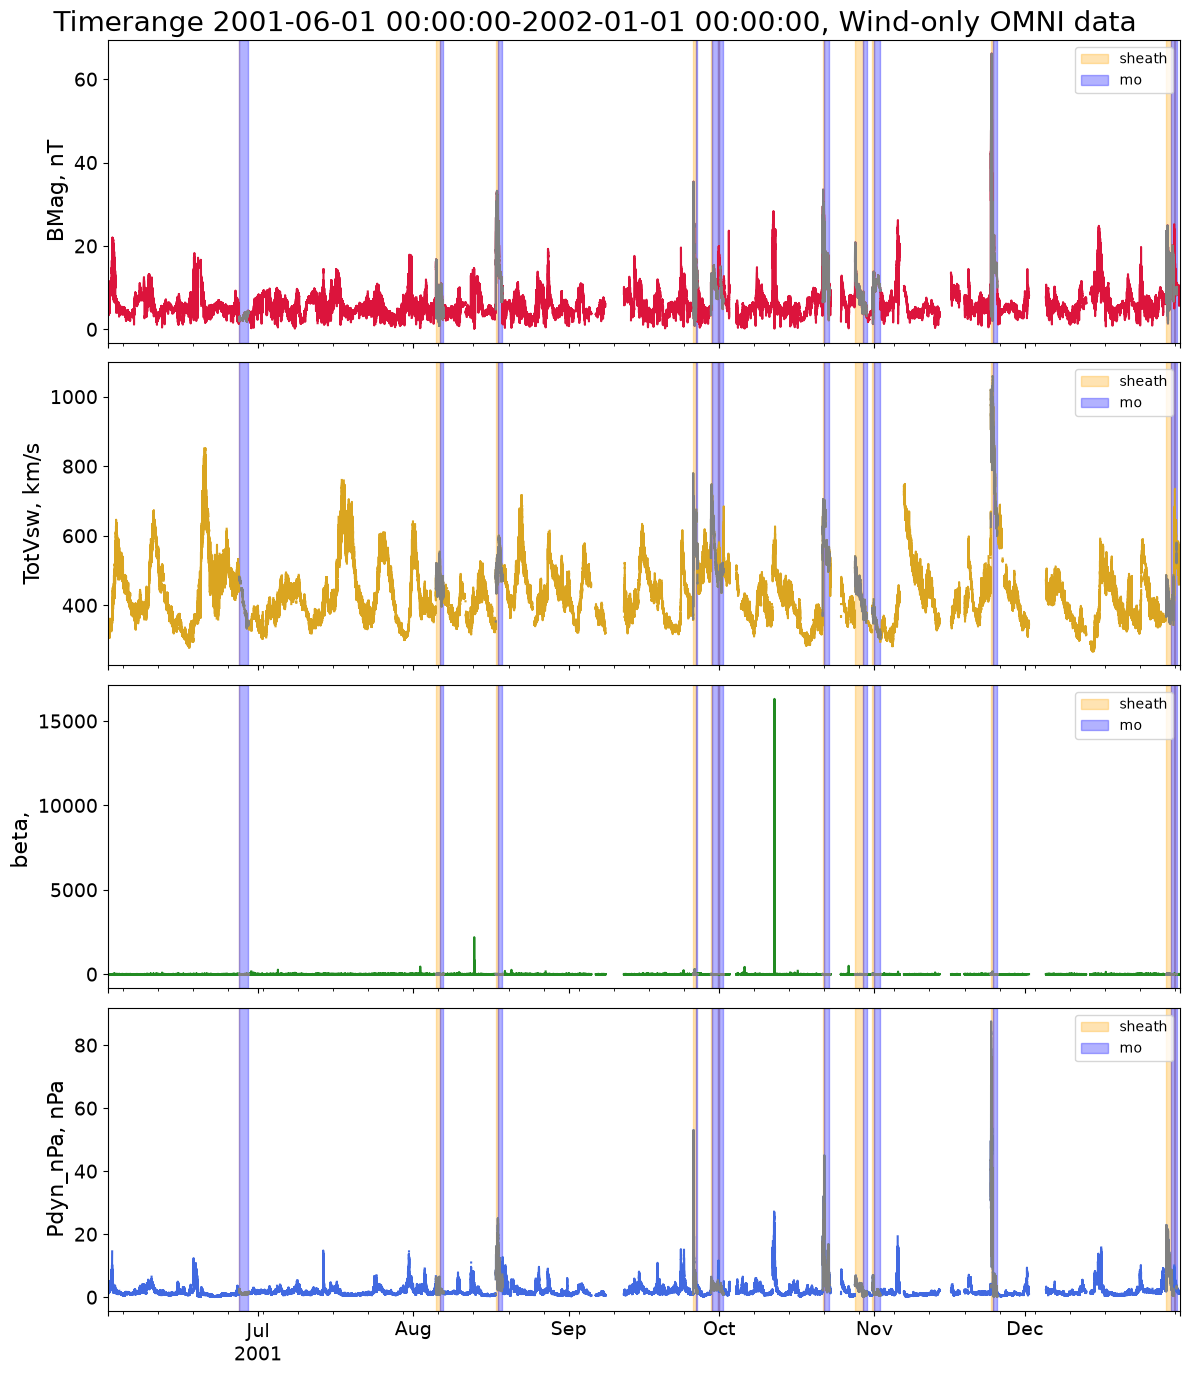

In [77]:
beginning = "2001-06-01 00:00:00"
ending = "2002-01-01 00:00:00"
CMEInvestigate(windData, parameters, parameters_units, [beginning, ending], icmes_in_timerange)

### Shorter timerange

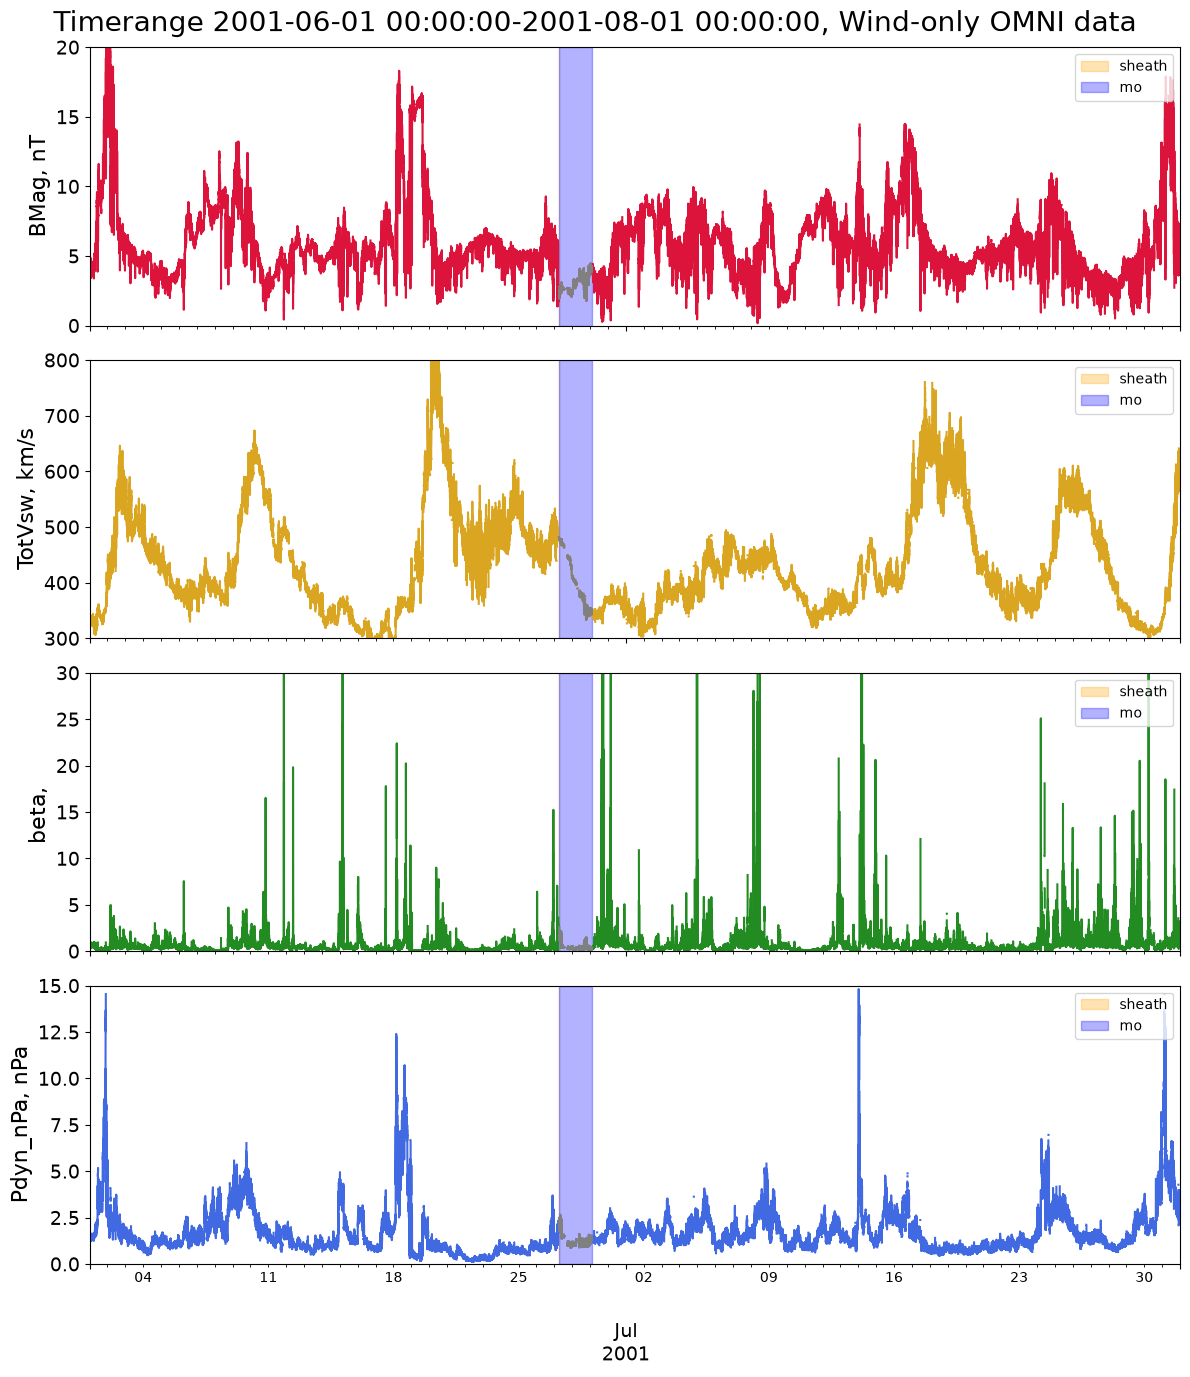

In [64]:
beginning = "2001-06-01 00:00:00"
ending = "2001-08-01 00:00:00"

CMEInvestigate(windData, parameters, parameters_units, [beginning, ending], icmes_in_timerange, ylims = [[0,20], [300, 800],[0,30],[0, 15]])



## Zoom in around CMEs

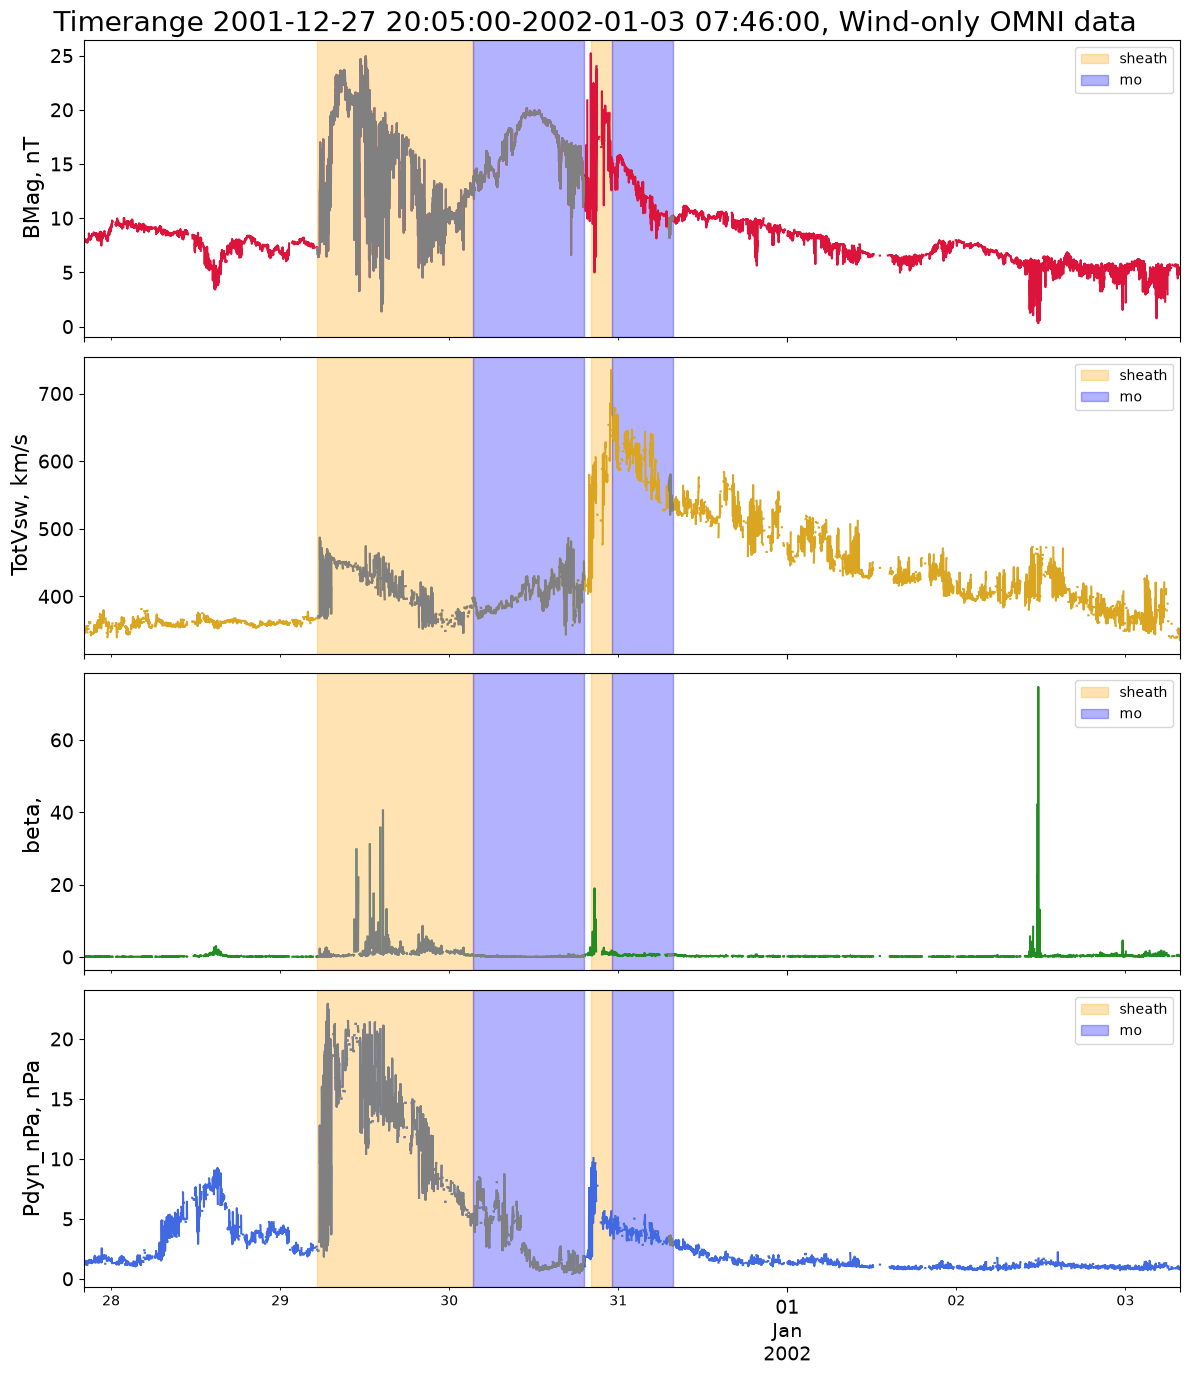

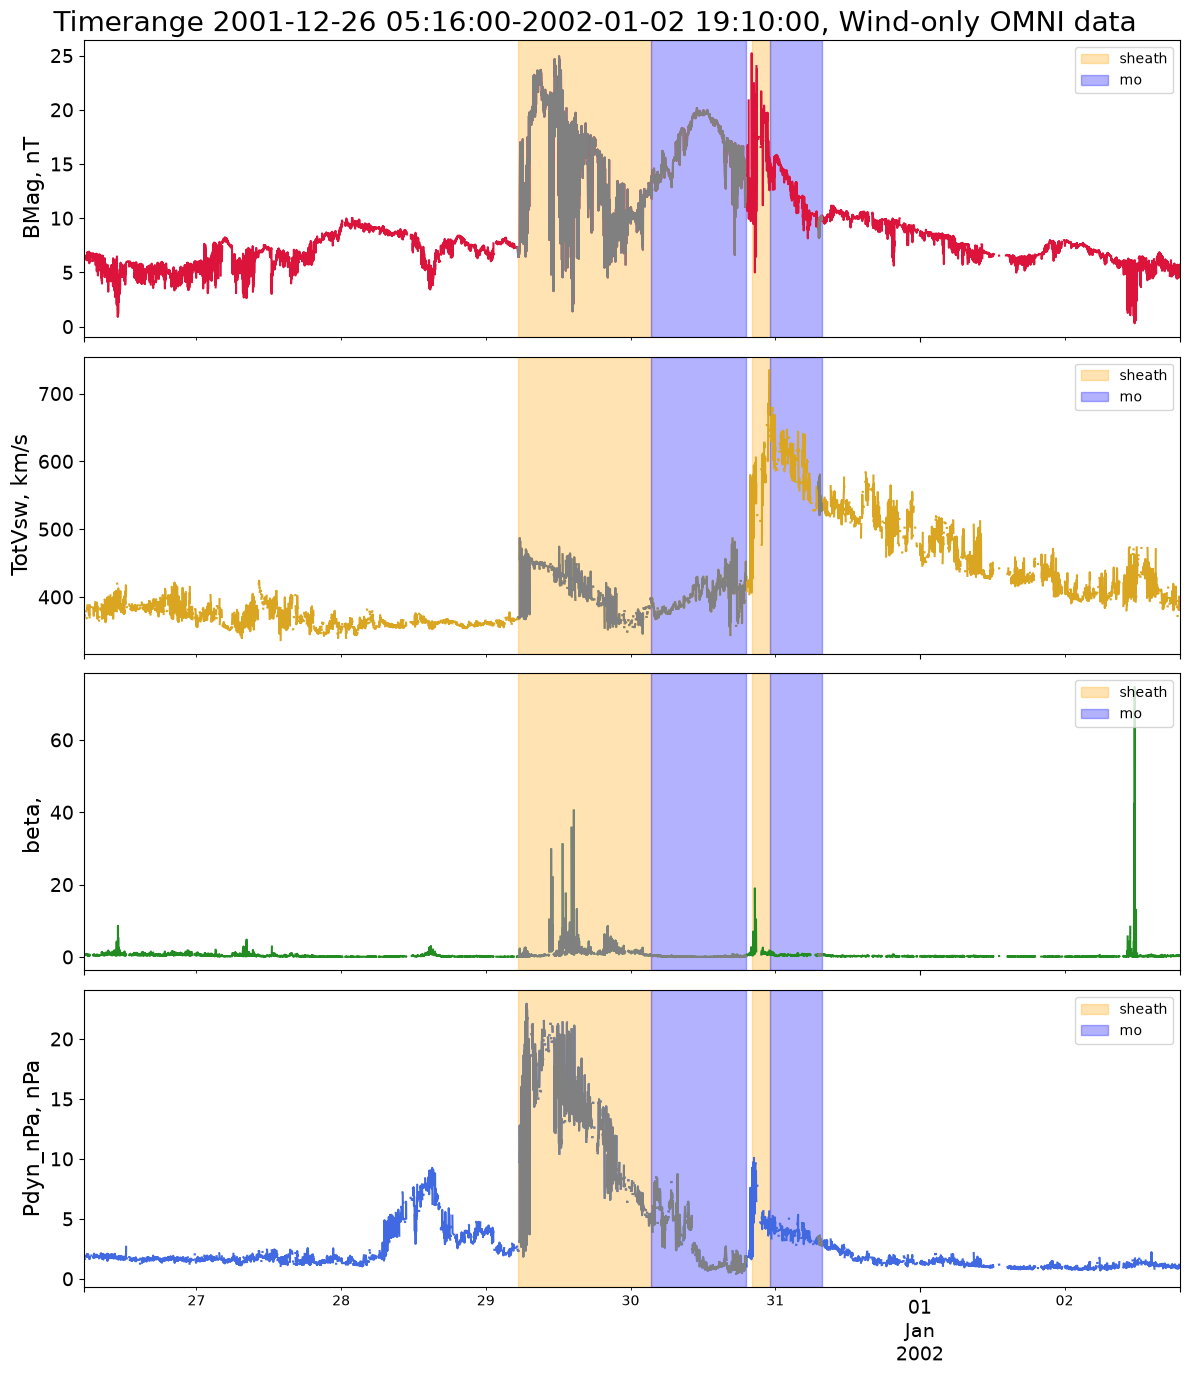

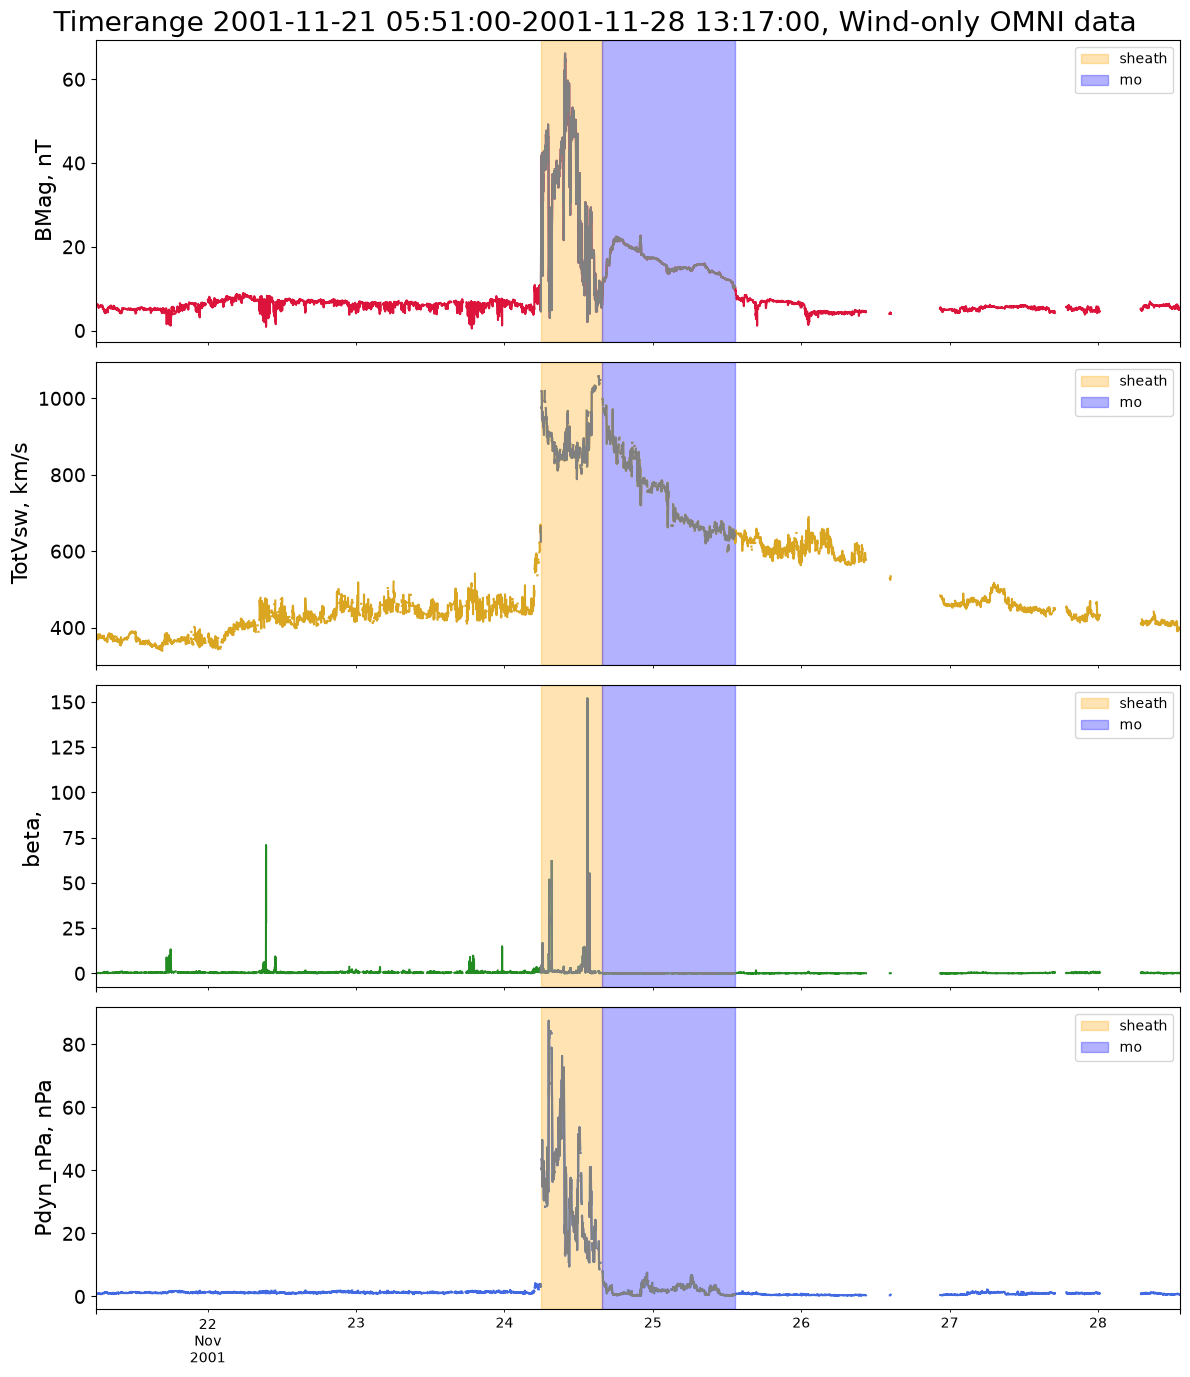

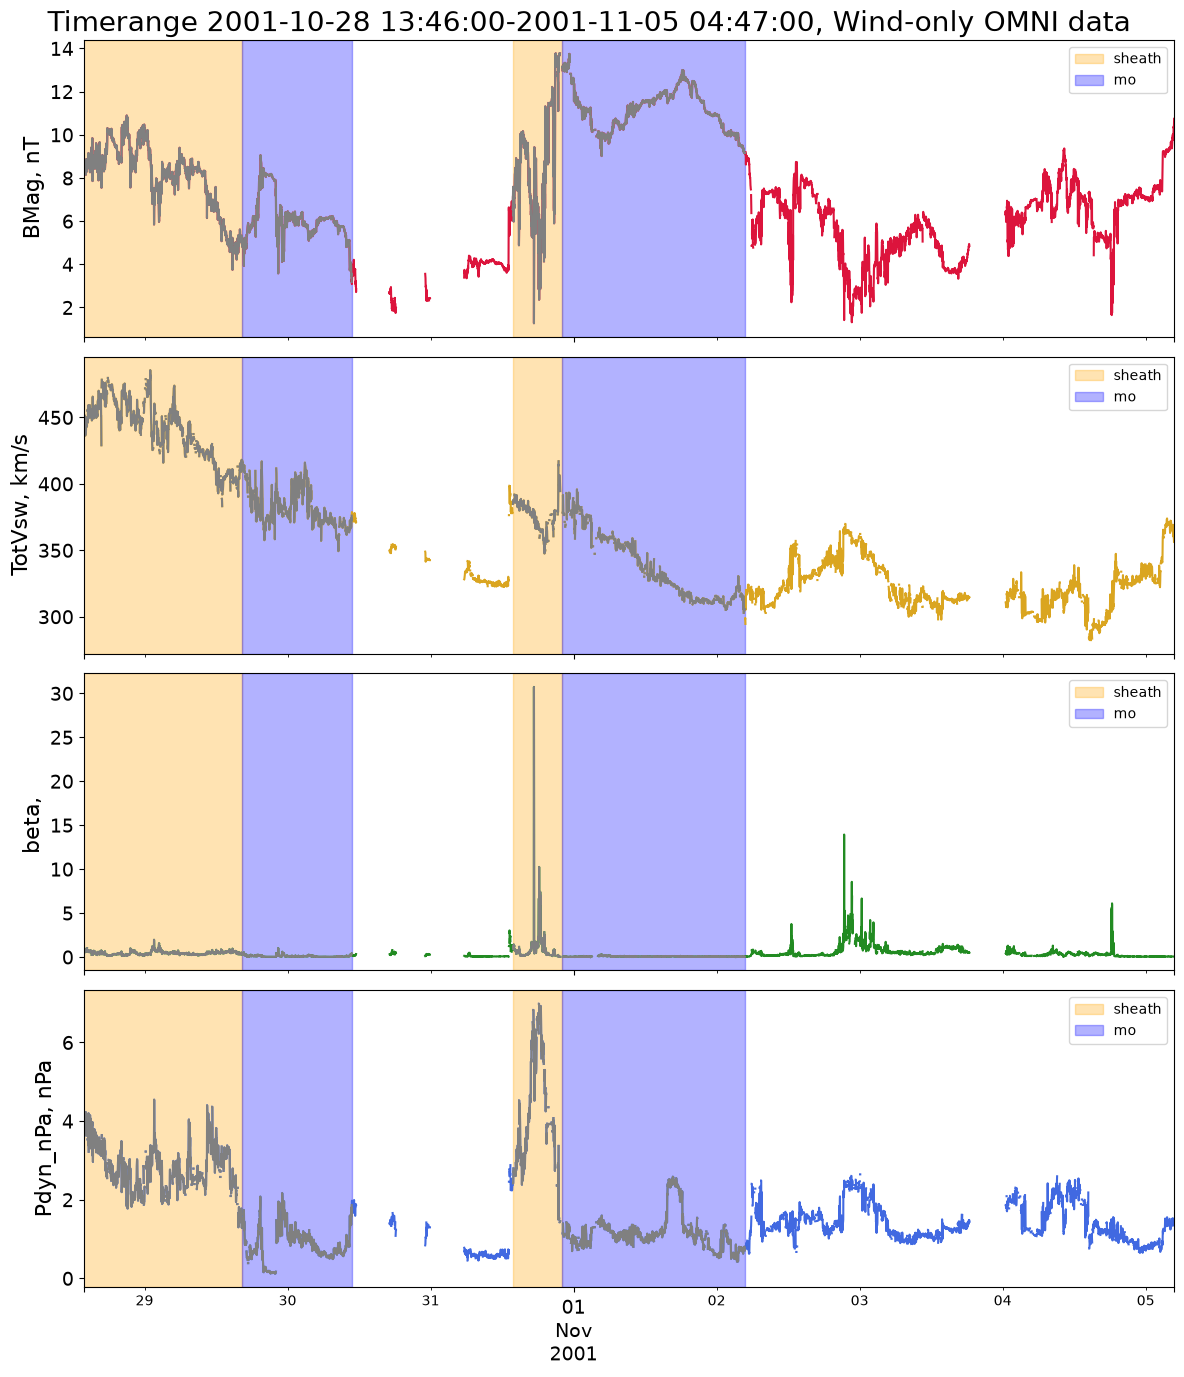

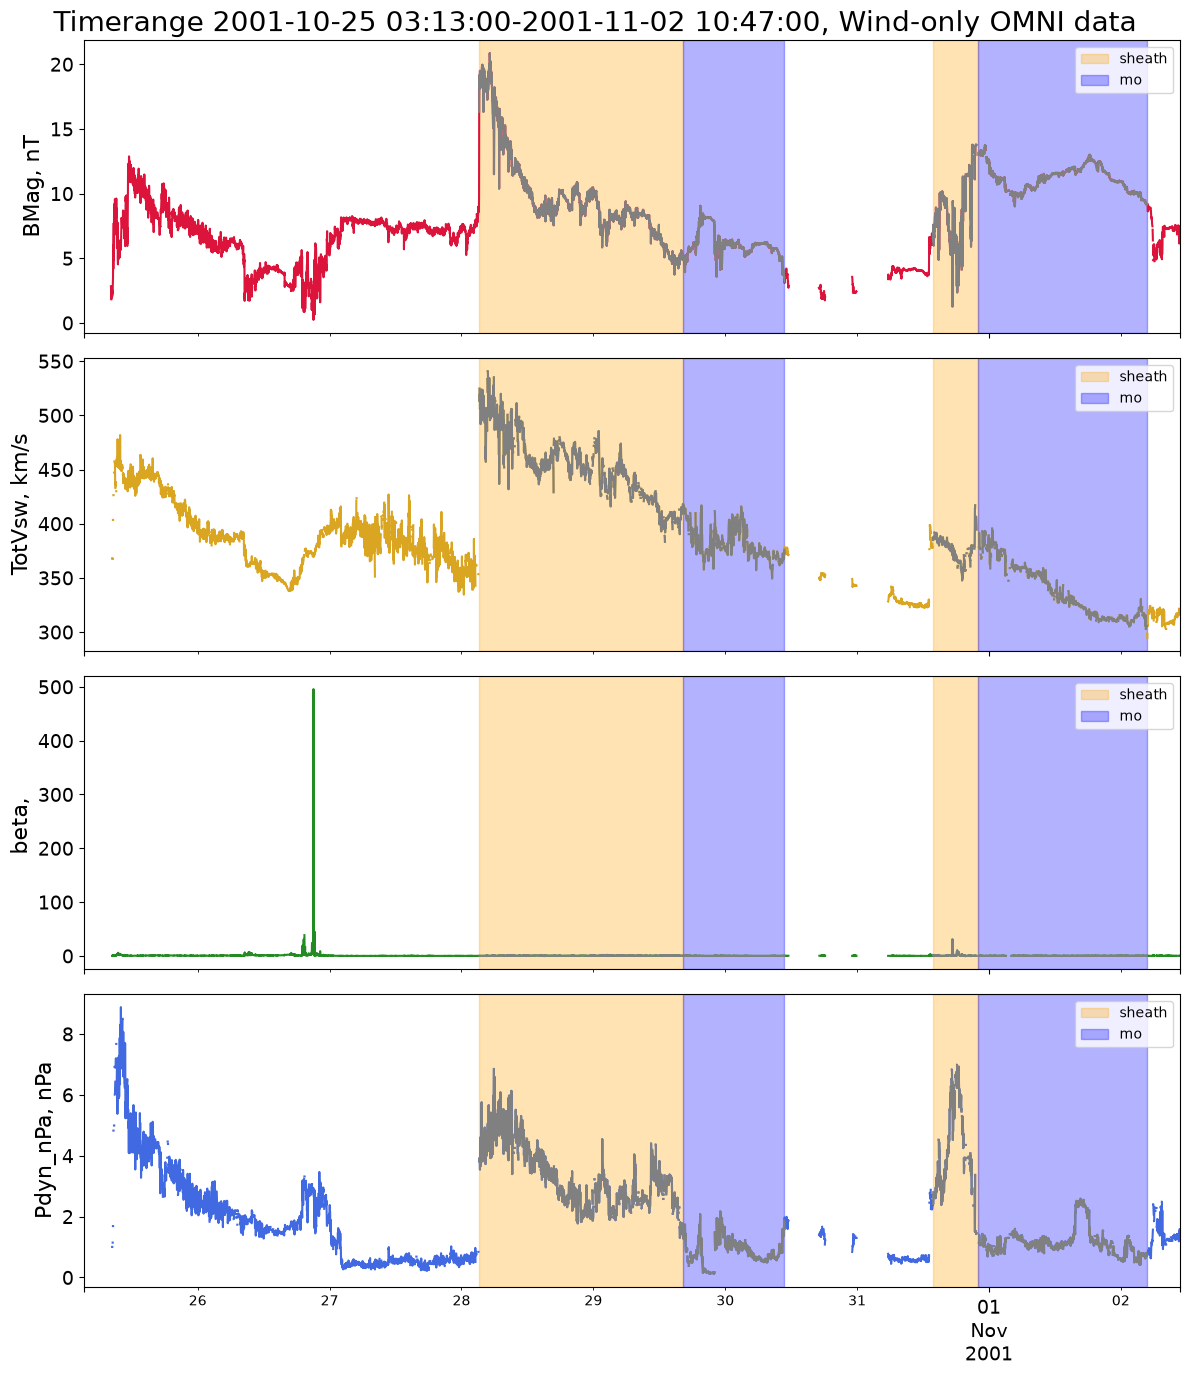

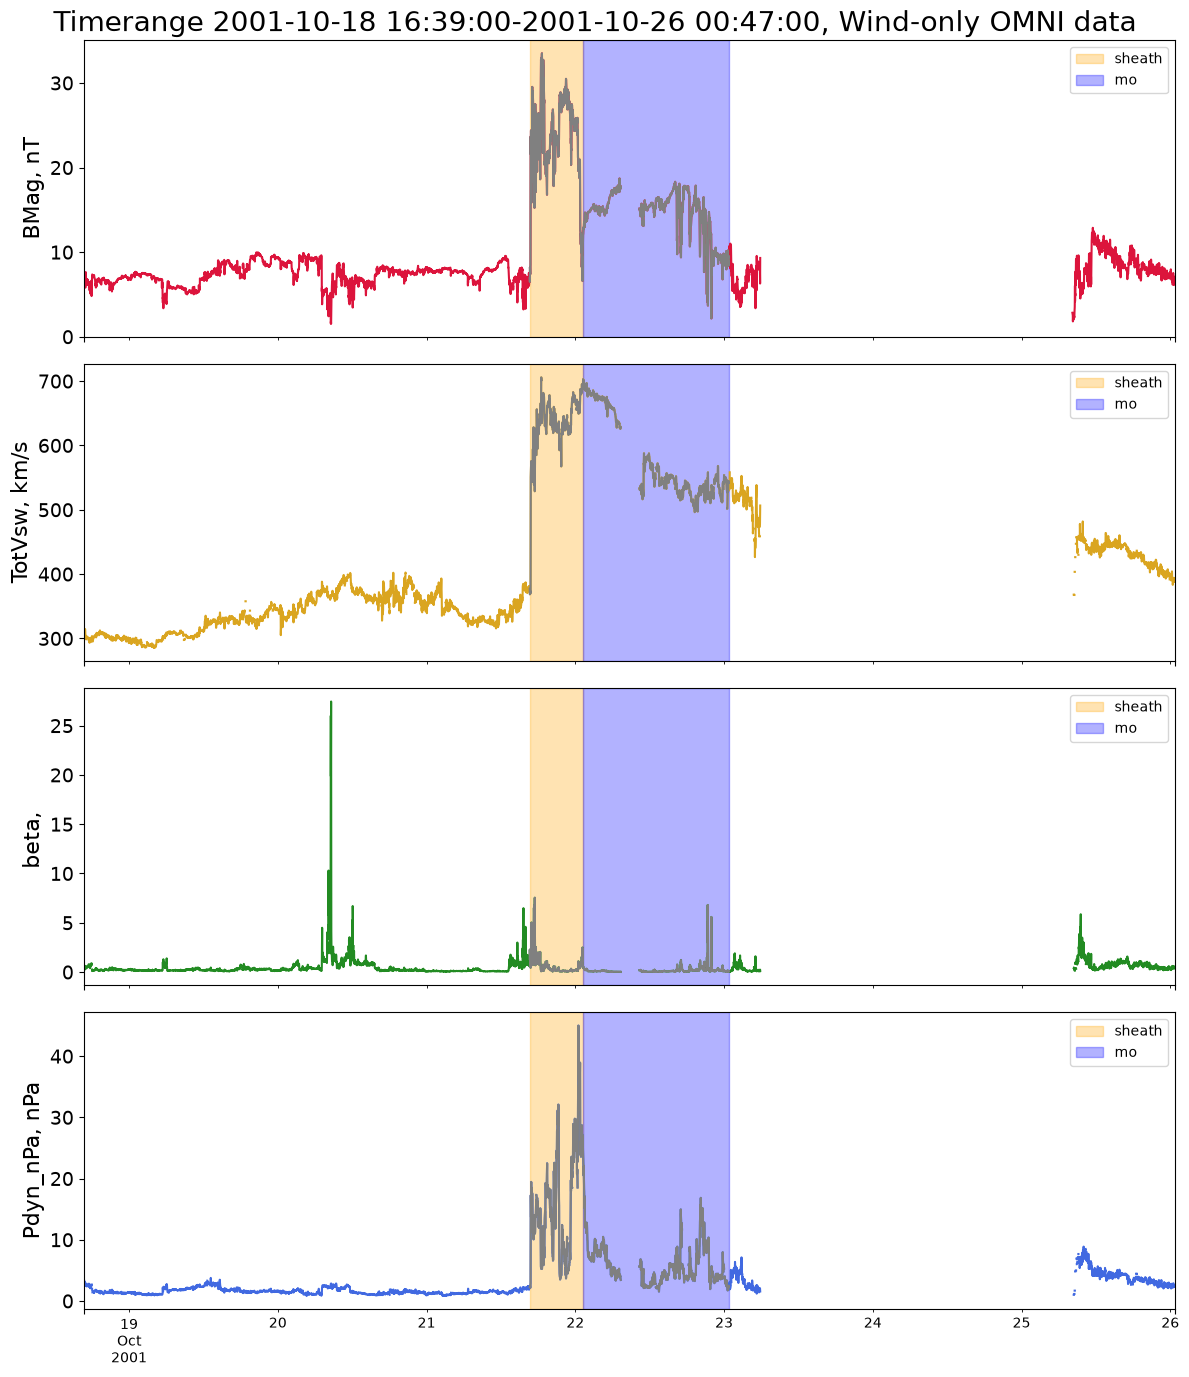

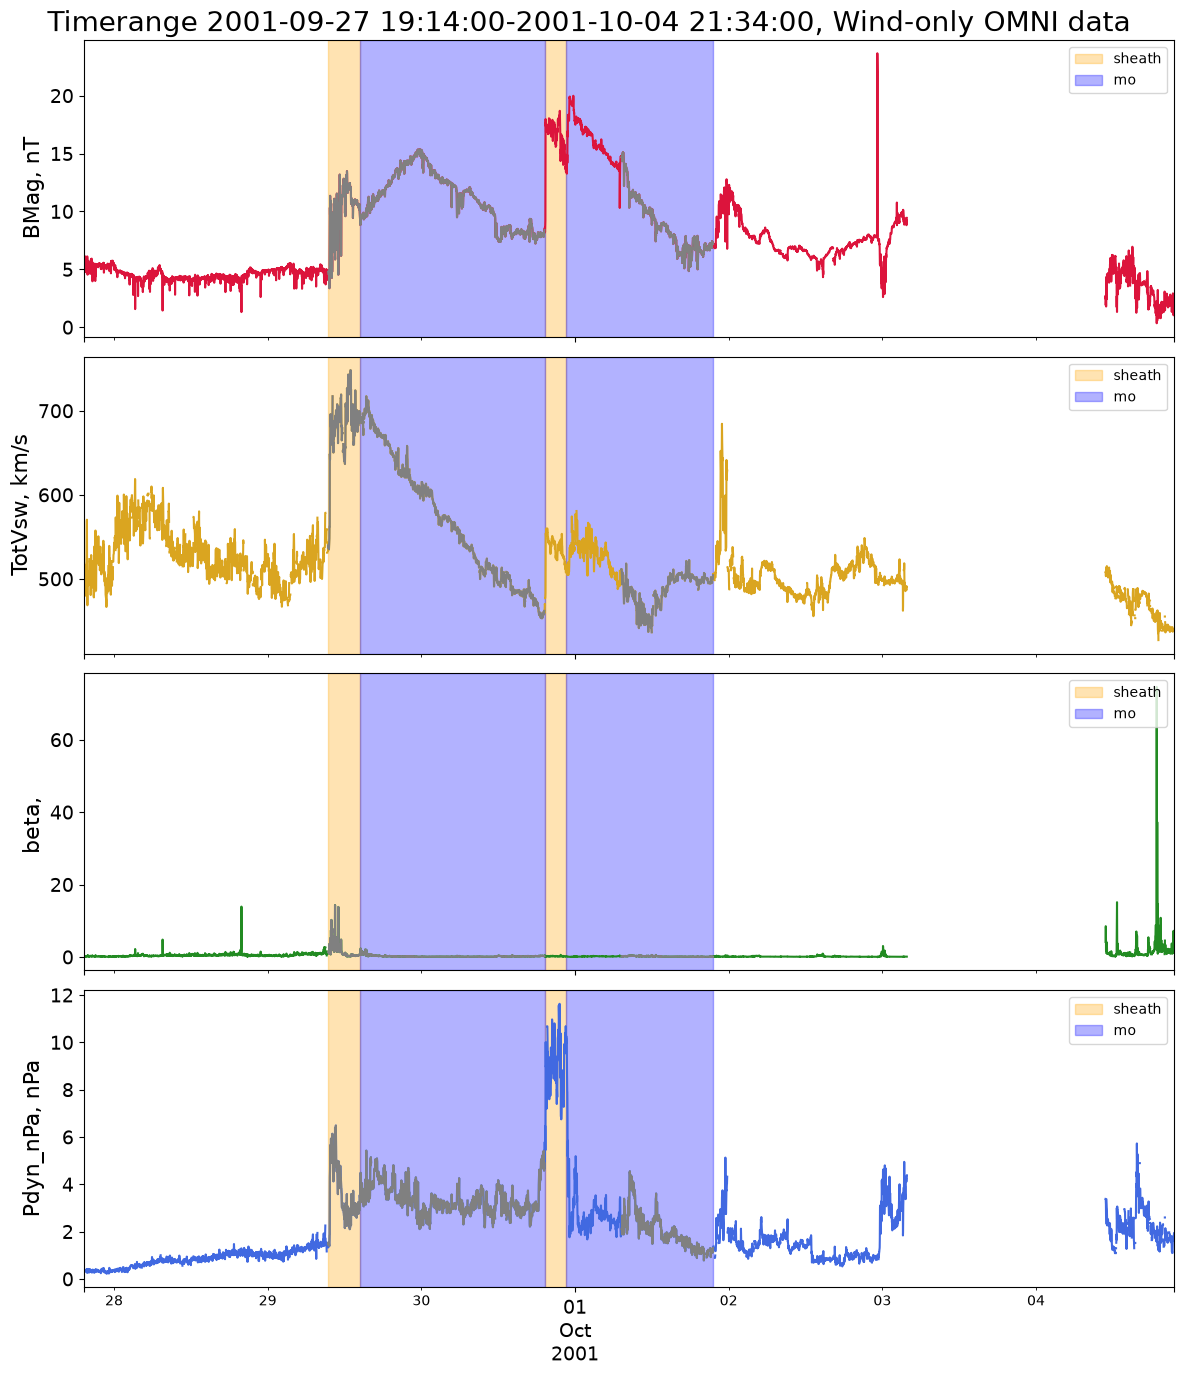

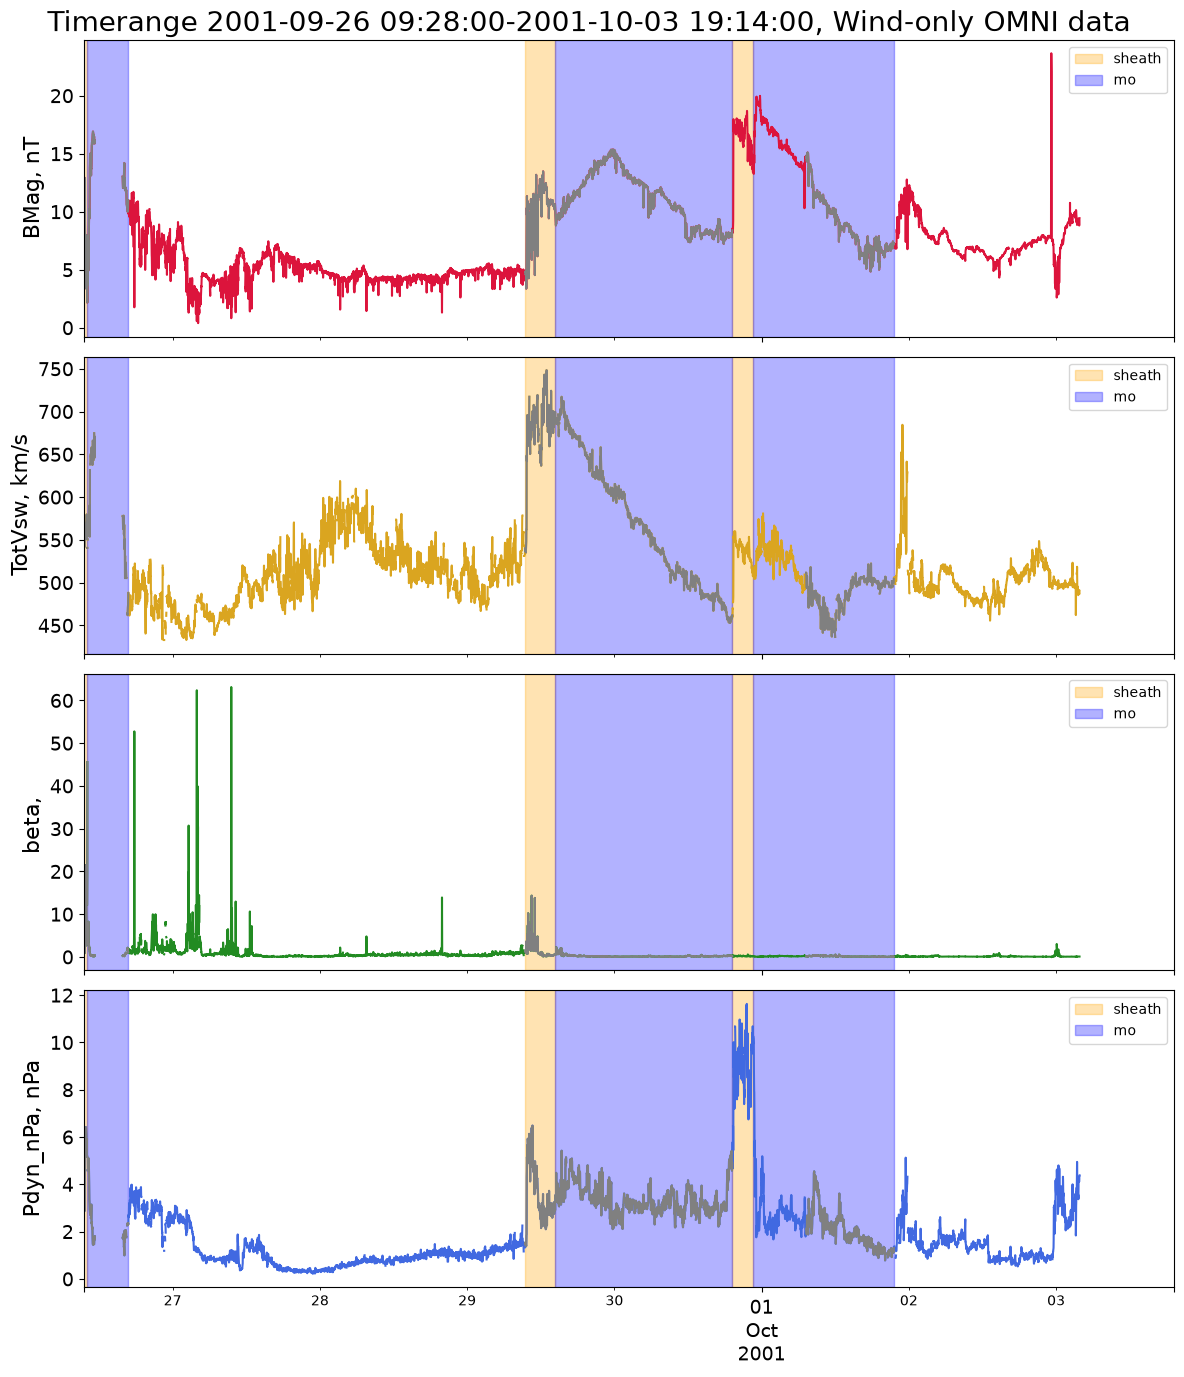

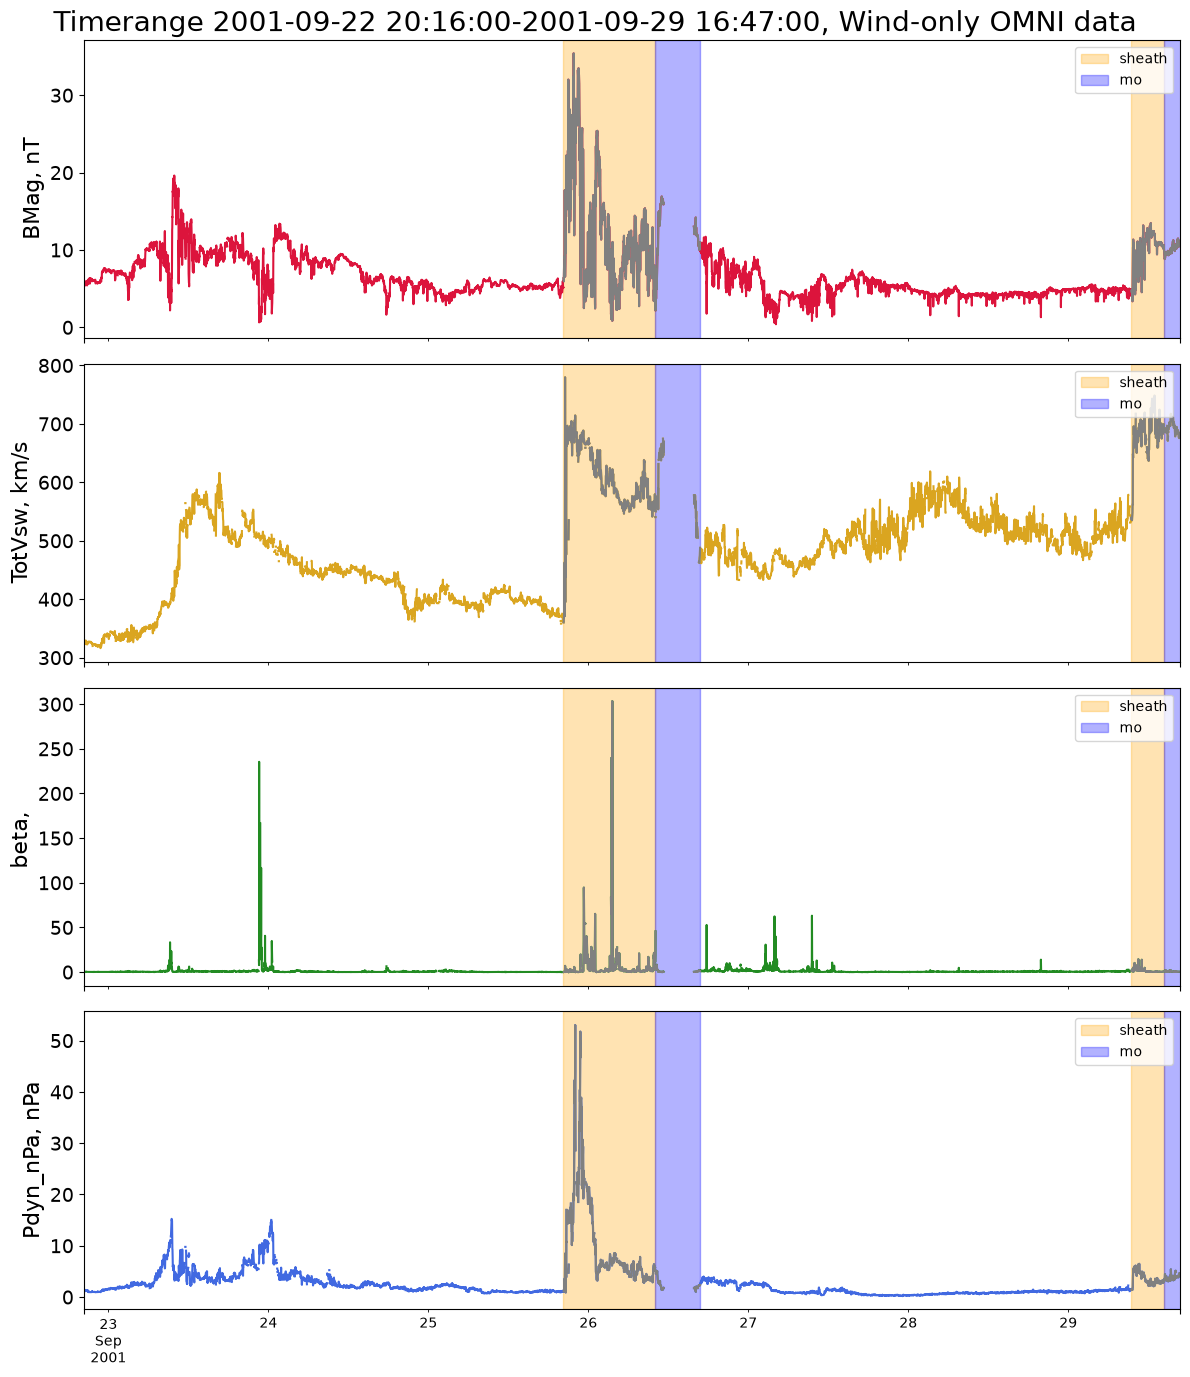

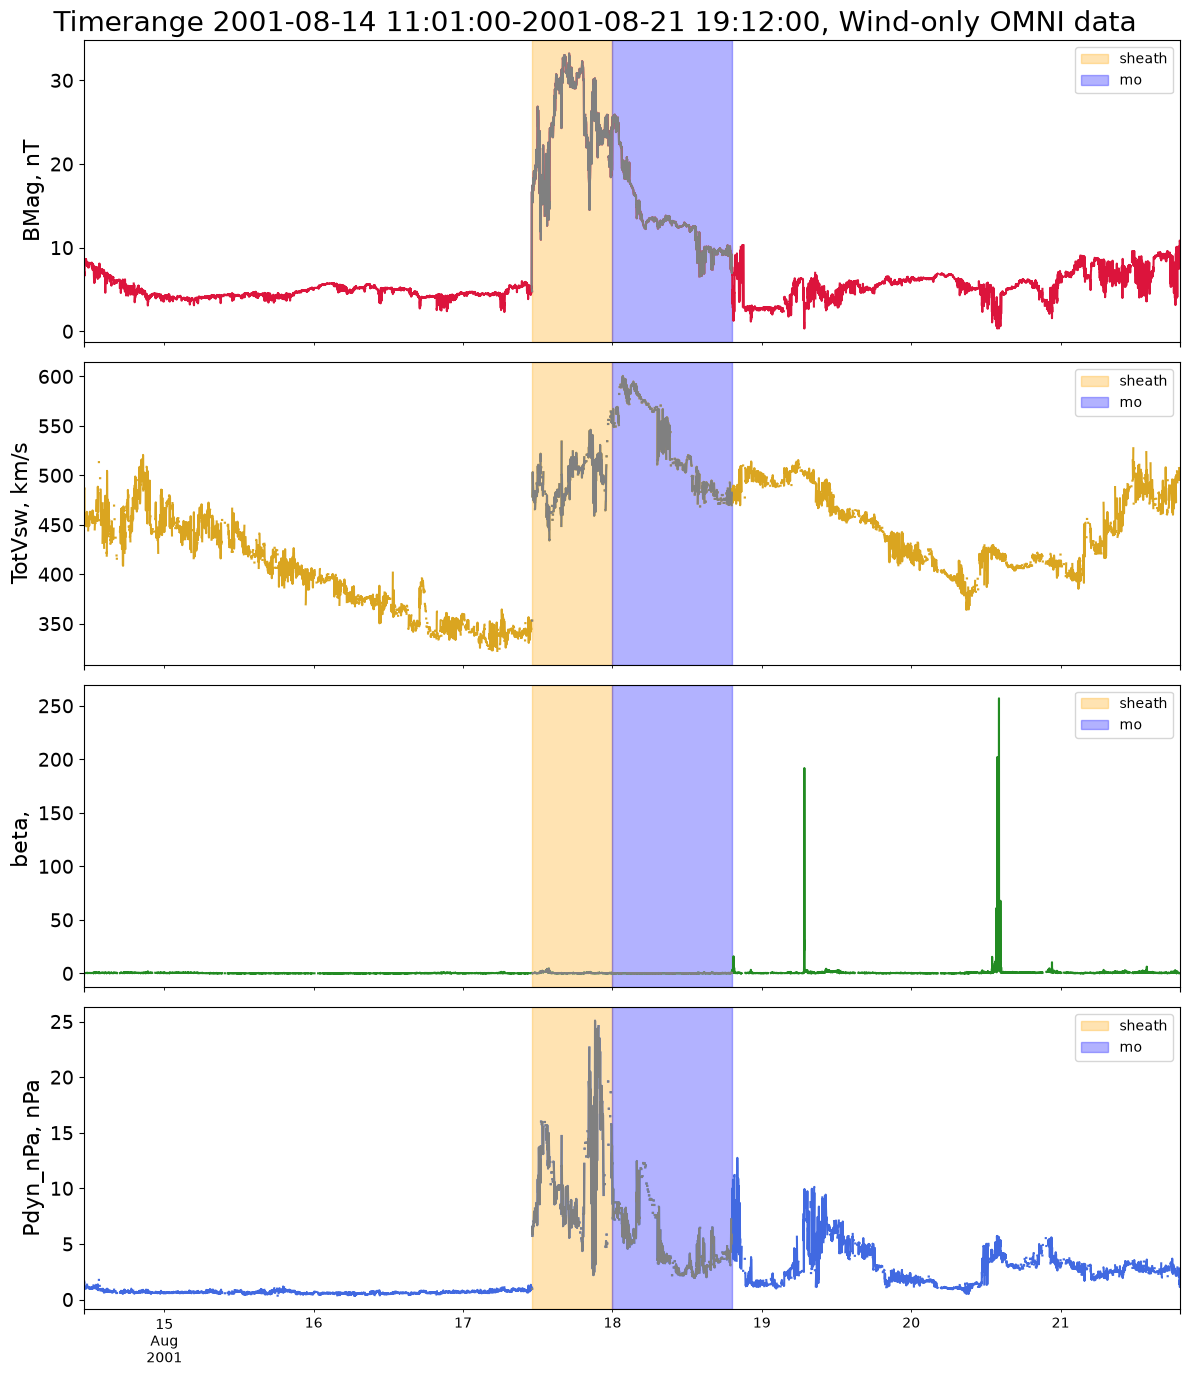

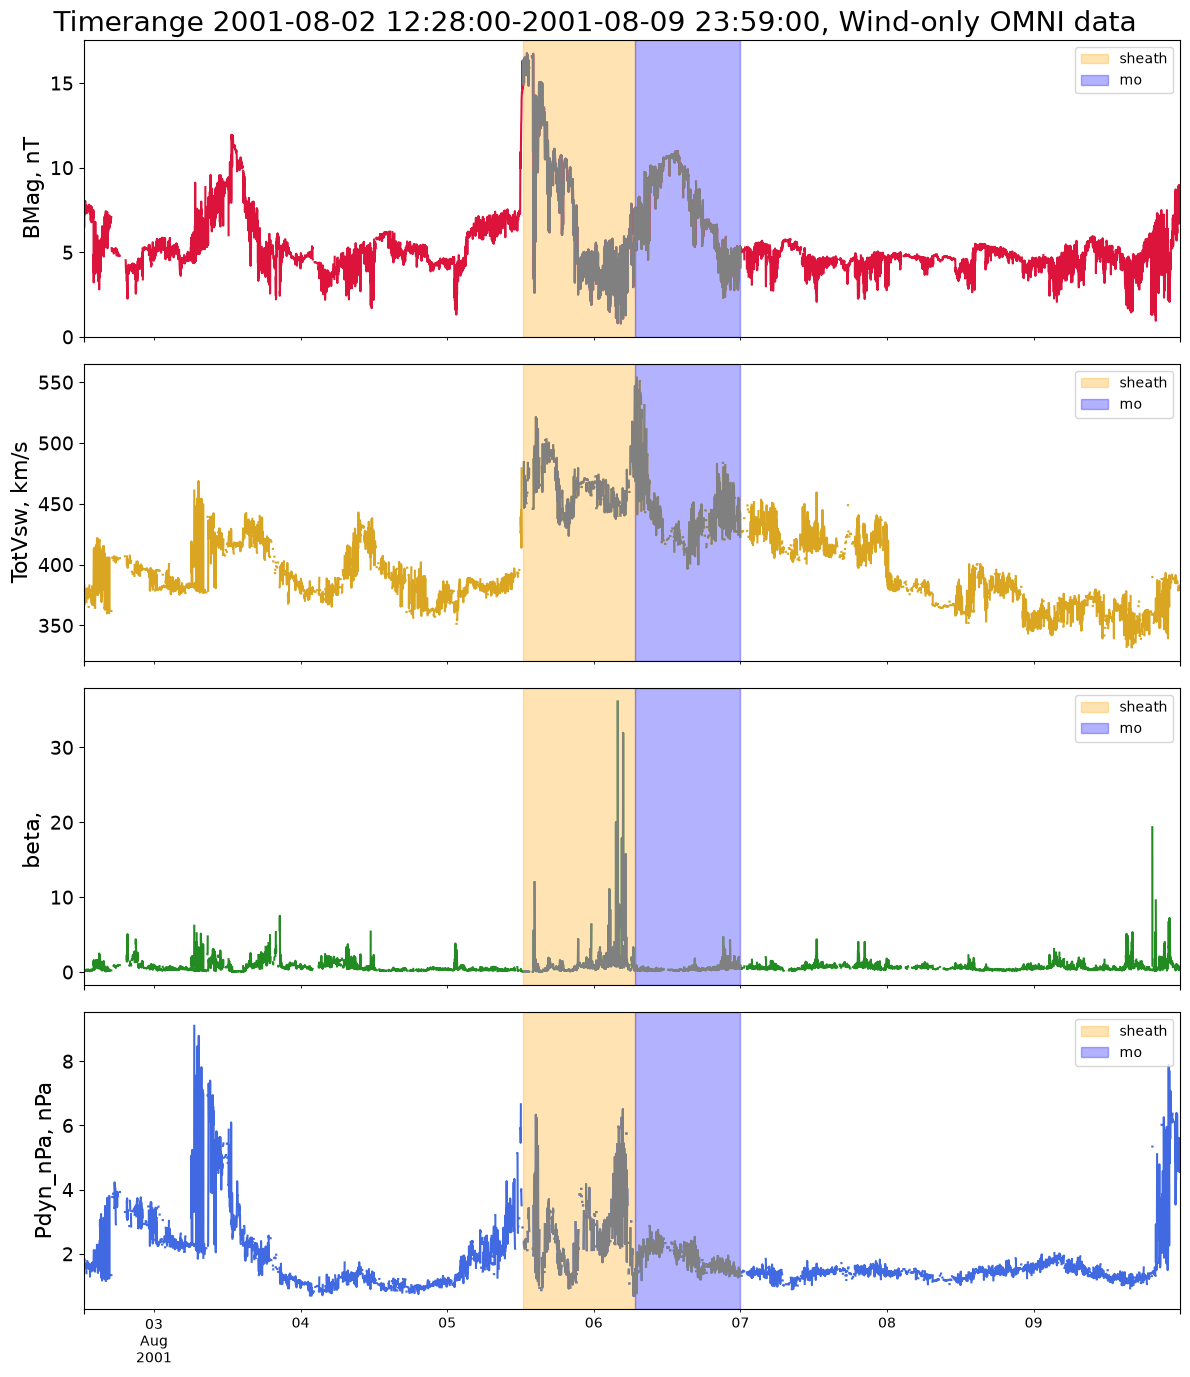

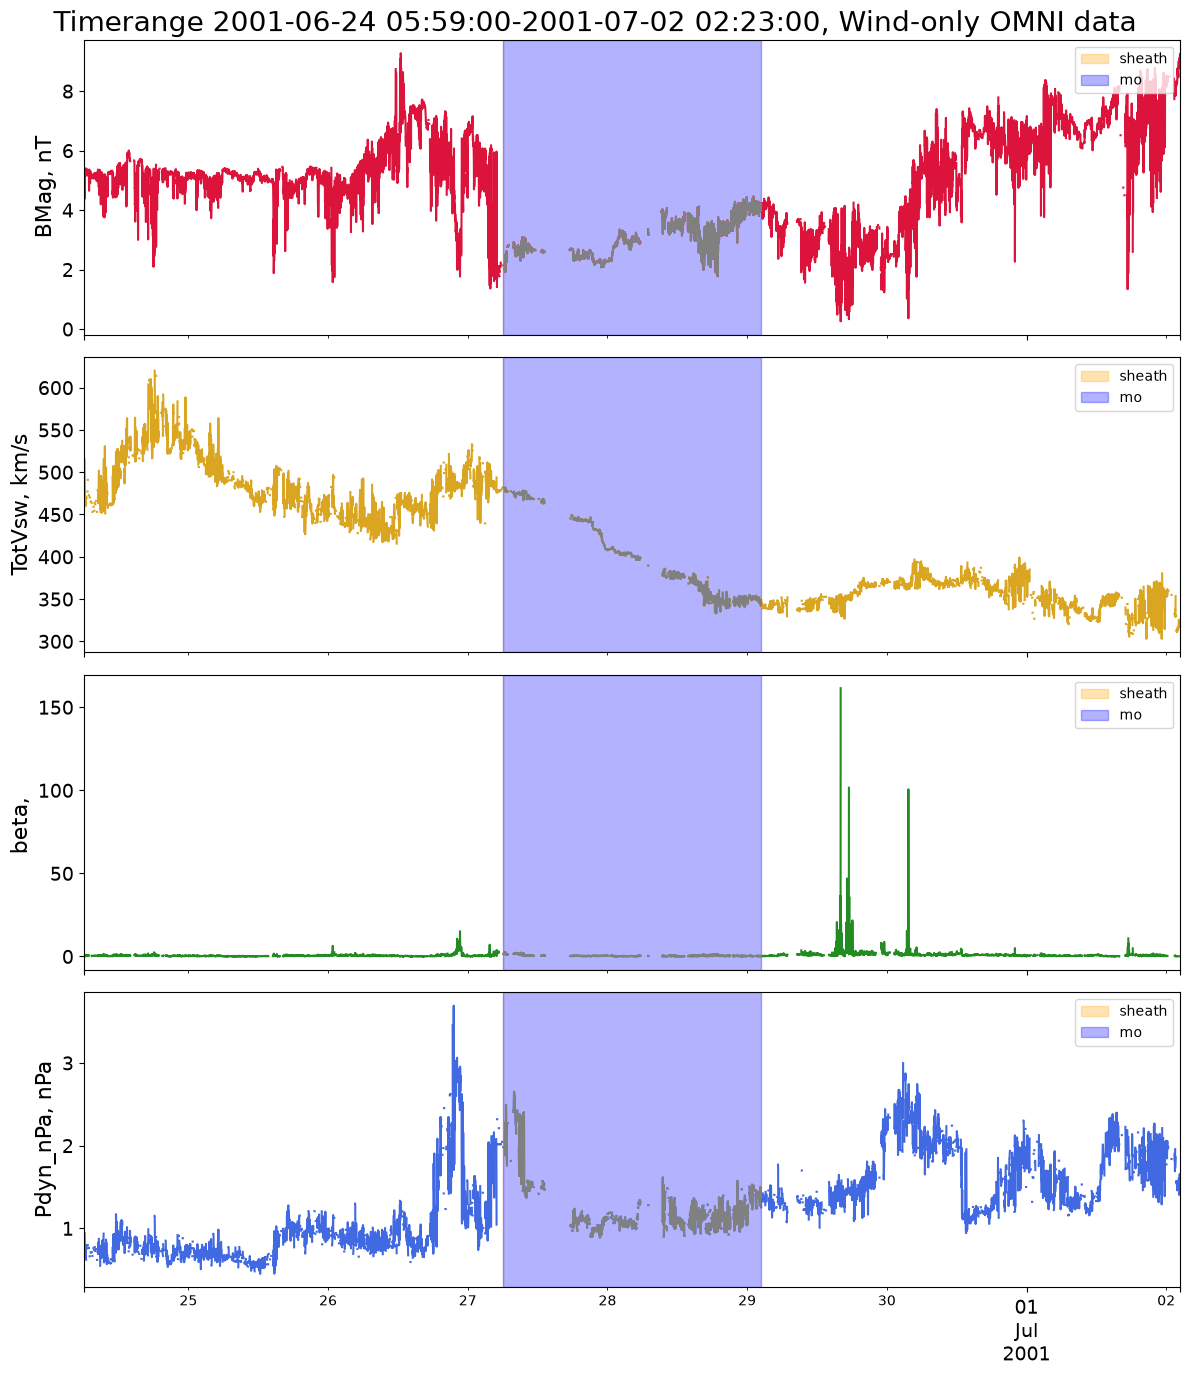

In [76]:
Days = 3
for i in range(len(icmes_in_timerange)):
    beginning = pd.to_datetime(icmes_in_timerange.icme_start_time[i]) - timedelta(days=Days)
    ending = pd.to_datetime(icmes_in_timerange.mo_end_time[i]) + timedelta(days=Days)
    # print(beginning, ending)

    CMEInvestigate(windData, parameters, parameters_units, [beginning, ending], icmes_in_timerange)#, ylims = [[0,20], [300, 800],[0,30],[0, 15]])
